# Effectiveness of thrombolysis and thrombectomy in early (6hr) arrivals of non-mild stroke - Target trial emulation

**Good outcome = discharged mRS or at same mRS as pre-stroke mRS**

See: https://www.nice.org.uk/corporate/ecd9/chapter/overview

Hernán MA, Dahabreh IJ, Dickerman BA, Swanson SA. The Target Trial Framework for Causal Inference From Observational Data: Why and When Is It Helpful? Ann Intern Med. 2025 Mar;178(3):402-407. doi: 10.7326/ANNALS-24-01871.

Cashin, A. G.; Hansford, H. J.; Hernán, M. A.; Swanson, S. A.; Lee, H.; Jones, M. D.; Dahabreh, I. J.; Dickerman, B. A.; Egger, M.; Garcia-Albeniz, X.; Golub, R. M.; Islam, N.; Lodi, S.; Moreno-Betancur, M.; Pearson, S.-A.; Schneeweiss, S.; Sharp, M. K.; Sterne, J. A. C.; Stuart, E. A.; McAuley, J. H. Transparent Reporting of Observational Studies Emulating a Target Trial—The TARGET Statement. 

JAMA 2025, 334 (12), 1084–1093. https://doi.org/10.1001/jama.2025.13350

BMJ 2025. https://doi.org/10.1136/bmj-2025-087179

YouTube videos on Target Trial Emulation:

https://www.youtube.com/watch?v=eWImwOCZndU

https://www.youtube.com/watch?v=UhmW4U_9vvA

## Overview

### The target trial being emulated

| Protocol component | Target trial | How it is emulated with SSNAP data |
|---|---|---|
| **Eligibility** | Ischaemic stroke, arriving within 6 hours of onset, non-mild (NIHSS > 5) or with a large vessel occlusion (LVO) | Infarction; onset-to-arrival < 360 min; NIHSS > 5 or LVO recorded; discharge mRS recorded; no perfusion imaging; stroke team gave at least 10 thrombectomies in the cohort |
| **Treatment strategies** | Seven strategies defined by whether, and how soon after onset, thrombolysis and/or thrombectomy are given, compared with neither | Treatment group assigned from recorded onset-to-treatment times; early = thrombolysis within 270 min or thrombectomy before 270 min |
| **Assignment** | Random | Not random. Each treated patient is exactly matched to an untreated patient with the same pre-stroke mRS, NIHSS band, age, AF anticoagulant use and AF diagnosis |
| **Outcomes** | Good outcome at discharge: mRS 0–2, or no worse than pre-stroke mRS. Secondary: discharge mRS, length of stay | As target trial |
| **Causal contrast** | Effect of treatment in those treated | Difference between matched treated and matched untreated patients |
| **Analysis** | Difference in proportions with 95% CI | Pooled-variance two-sample *t* interval; sensitivity analyses at the end |

### Notebook structure

1. Settings and fields
2. Cohort selection and treatment strategies
3. Matching
4. Outcomes: good outcome, discharge mRS, length of stay
5. Balance of patient characteristics after matching
6. Plot of main results
7. Sensitivity analyses
8. Conclusions and limitations

### Key findings

* All seven treatment strategies are associated with a higher proportion of patients with a good outcome at discharge than in matched untreated patients. Differences range from **6.3 percentage points** (late thrombolysis only) to **23.5 percentage points** (early thrombolysis plus early thrombectomy).
* Earlier treatment is associated with larger benefit: thrombolysis only 12.4 (early) vs 6.3 (late) points; thrombectomy only 17.2 (early) vs 8.3 (late) points.
* The results are robust to most sensitivity analyses. The thrombectomy estimates are the most sensitive:
  * they fall when comorbidities are added to the matching (thrombectomy patients have less diabetes than their controls)
  * they rise when matching also on LVO, in the minority of patients for whom that is possible
  * they vary by a few points with the random choice of control

## Settings

In [1]:
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

In [2]:
# ---------- Analysis settings ----------
prefix = "non_mild_stroke_early_arrival_good_outcome_target_trial"  # stem for output file names
DATA_PATH = "../data/sam3/cleaned_data.csv"
OUTPUT_DIR = "./output"

MRS_TARGET = 2          # good outcome: discharge mRS <= MRS_TARGET, or no worse than pre-stroke mRS
CUTOFF = 270            # minutes from onset separating early from late treatment
MAX_CONTROL_REUSE = 3   # k: maximum number of times each control patient can be used as a match
MATCH_SEED = 42         # base random seed for picking a control within a matching stratum
NO_TREATMENT = 99999    # sentinel time meaning "treatment not given"

TIME_THROMBOLYSIS = "onset_to_thrombolysis_time"
TIME_THROMBECTOMY = "onset_to_thrombectomy_time"

## Define fields

* **Baseline features** are measured before treatment. They are used to check that matched treated and untreated patients are similar.
* **Outcome features** are recorded after treatment. They are described for each group but never used for matching.
* **Matching features** are the baseline features that treated and control patients must share exactly. Stroke severity is matched in 5-point NIHSS bands (0–4, 5–9, 10–14, …) rather than exact score, so that most treated patients can find a match.

In [3]:
# Patient characteristics measured before treatment
BASELINE_FEATURES = [
    'prior_disability',
    'stroke_severity',
    'age',
    'congestive_heart_failure',
    'hypertension',
    'diabetes',
    'afib_anticoagulant',
    'any_afib_diagnosis',
]

# Events and outcomes after treatment (described only)
OUTCOME_FEATURES = [
    'length_of_stay',
    'discharge_disability',
    'thrombolysis_induced_haemorrhage',
    'death',
]

DESCRIPTIVE_FEATURES = BASELINE_FEATURES + OUTCOME_FEATURES

# Treated and control patients must have identical values of all of these
MATCHING_FEATURES = [
    'prior_disability',
    'stroke_severity_band',
    'age',
    'afib_anticoagulant',
    'any_afib_diagnosis',
]

# Columns kept from the raw data
ALL_FEATURES = list(dict.fromkeys(DESCRIPTIVE_FEATURES + ['lvo', TIME_THROMBOLYSIS, TIME_THROMBECTOMY]))

# Treatment strategies, in display order, with labels for plots
CONTROL_GROUP = "neither"
GROUP_ORDER = [
    'early_thrombolysis_only',
    'late_thrombolysis_only',
    'early_thrombectomy_only',
    'late_thrombectomy_only',
    'early_both',
    'early_thrombolysis_late_thrombectomy',
    'late_both',
]
GROUP_LABELS = {
    'early_thrombolysis_only': 'Early Thrombolysis\nOnly',
    'late_thrombolysis_only': 'Late Thrombolysis\nOnly',
    'early_thrombectomy_only': 'Early Thrombectomy\nOnly',
    'late_thrombectomy_only': 'Late Thrombectomy\nOnly',
    'early_both': 'Early Both',
    'early_thrombolysis_late_thrombectomy': 'Early Thrombolysis\nLate Thrombectomy',
    'late_both': 'Late Both',
}

## Cohort selection and treatment strategies

### Eligibility

Patients are included if they:

* had an ischaemic stroke (infarction) and a recorded discharge mRS
* arrived within 6 hours (360 minutes) of stroke onset
* did not have perfusion imaging. Perfusion imaging is mostly used to select patients for late thrombectomy, so excluding it keeps the cohort to patients assessed in the conventional way.
* had a non-mild stroke (NIHSS > 5) **or** a recorded large vessel occlusion
* were treated by a stroke team that gave at least 10 thrombectomies in this cohort, so all patients were seen by teams with access to thrombectomy.

Records with implausible treatment times are removed: thrombolysis after thrombectomy, thrombectomy 12 hours or more after onset, and thrombolysis 6 hours or more after onset.

### Treatment strategies

Each patient is assigned to one strategy from their onset-to-treatment times. "Early" means thrombolysis within 270 minutes (4.5 hours) of onset, or thrombectomy before 270 minutes.

| Strategy | Thrombolysis | Thrombectomy |
|---|---|---|
| neither (control) | no | no |
| early thrombolysis only | ≤ 270 min | no |
| late thrombolysis only | > 270 min | no |
| early thrombectomy only | no | < 270 min |
| late thrombectomy only | no | ≥ 270 min |
| early both | ≤ 270 min | < 270 min |
| early thrombolysis, late thrombectomy | ≤ 270 min | ≥ 270 min |
| late both | > 270 min | > 270 min |

**Edge case:** a patient with late thrombolysis and thrombectomy at exactly 270 minutes matches none of these rules, so they are counted as "neither". This is kept so that results match earlier versions of the analysis. Changing `>` to `>=` in the "late both" rule would fix it.

In [4]:
def good_outcome(df, mrs_target=MRS_TARGET, allow_no_worse_than_prior=True):
    # 1 if discharge mRS <= mrs_target, or (optionally) discharge mRS no worse than pre-stroke mRS
    outcome = df["discharge_disability"] <= mrs_target
    if allow_no_worse_than_prior:
        outcome = outcome | (df["discharge_disability"] <= df["prior_disability"])
    return outcome.astype(int)


def assign_treatment_groups(df, cutoff=CUTOFF):
    # Label each patient with a treatment strategy. Rules are applied in order;
    # later rules overwrite earlier ones (e.g. 'early_both' overwrites single-treatment labels).
    lysis, ect = df[TIME_THROMBOLYSIS], df[TIME_THROMBECTOMY]
    has_lysis, has_ect = lysis != NO_TREATMENT, ect != NO_TREATMENT

    group = pd.Series(CONTROL_GROUP, index=df.index)
    group[(lysis <= cutoff) & ~has_ect] = "early_thrombolysis_only"
    group[(lysis > cutoff) & has_lysis & ~has_ect] = "late_thrombolysis_only"
    group[~has_lysis & (ect < cutoff)] = "early_thrombectomy_only"
    group[~has_lysis & (ect >= cutoff) & has_ect] = "late_thrombectomy_only"
    group[(lysis <= cutoff) & (ect < cutoff)] = "early_both"
    group[(lysis <= cutoff) & (ect >= cutoff) & has_ect] = "early_thrombolysis_late_thrombectomy"
    group[(lysis > cutoff) & has_lysis & (ect > cutoff) & has_ect] = "late_both"  # see edge case above

    df["treatment_group"] = group
    return df


def build_cohort(raw, cutoff=CUTOFF, min_team_thrombectomies=10,
                 exclude_perfusion_imaging=True, verbose=False):
    # Apply the eligibility criteria and add derived columns.
    # Arguments allow the sensitivity analyses to change one choice at a time.
    df = raw
    log = [("All records", len(df))]

    def keep_rows(label, mask):
        nonlocal df
        df = df[mask]
        log.append((label, len(df)))

    keep_rows("Discharge mRS recorded", df["discharge_disability"].notna())
    keep_rows("Infarction", df["infarction"] == 1)
    keep_rows("Arrival within 360 min of onset", df["onset_to_arrival_time"] < 360)
    if exclude_perfusion_imaging:
        keep_rows("No perfusion imaging", df["perfusion_imaging_used"] == 0)
    keep_rows("NIHSS > 5 or LVO", (df["stroke_severity"] > 5) | (df["lvo"] == 1))

    team_counts = df.groupby("stroke_team")[TIME_THROMBECTOMY].count()
    eligible_teams = team_counts.index[team_counts >= min_team_thrombectomies]
    keep_rows(f"Team gave >= {min_team_thrombectomies} thrombectomies",
              df["stroke_team"].isin(eligible_teams))

    # Missing treatment time = treatment not given
    df = df.copy()
    df[TIME_THROMBOLYSIS] = df[TIME_THROMBOLYSIS].fillna(NO_TREATMENT)
    df[TIME_THROMBECTOMY] = df[TIME_THROMBECTOMY].fillna(NO_TREATMENT)
    lysis, ect = df[TIME_THROMBOLYSIS], df[TIME_THROMBECTOMY]

    keep_rows("Thrombolysis not after thrombectomy",
              ~((lysis < NO_TREATMENT) & (ect < NO_TREATMENT) & (lysis > ect)))
    keep_rows("Thrombectomy (if given) < 720 min", (df[TIME_THROMBECTOMY] < 720) | (df[TIME_THROMBECTOMY] == NO_TREATMENT))
    keep_rows("Thrombolysis (if given) < 360 min", (df[TIME_THROMBOLYSIS] < 360) | (df[TIME_THROMBOLYSIS] == NO_TREATMENT))

    df = df[ALL_FEATURES].copy()
    df["stroke_severity_band"] = (
        pd.to_numeric(df["stroke_severity"], errors="coerce").floordiv(5).astype("Int64")
    )
    df["outcome_target"] = good_outcome(df)
    df = assign_treatment_groups(df, cutoff)
    df["patient_id"] = np.arange(len(df))

    if verbose:
        display(pd.DataFrame(log, columns=["Step", "Patients remaining"]))
    return df


raw_data = pd.read_csv(DATA_PATH, low_memory=False)
data = build_cohort(raw_data, verbose=True)

,Step,Patients remaining
0,All records,452863
1,Discharge mRS recorded,438589
2,Infarction,384365
3,Arrival within 360 min of onset,163932
4,No perfusion imaging,161607
5,NIHSS > 5 or LVO,77938
6,Team gave >= 10 thrombectomies,75535
7,Thrombolysis not after thrombectomy,75514
8,Thrombectomy (if given) < 720 min,75124
9,Thrombolysis (if given) < 360 min,74678


In [5]:
# Number of patients in each treatment strategy
has_lysis = data[TIME_THROMBOLYSIS] != NO_TREATMENT
has_ect = data[TIME_THROMBECTOMY] != NO_TREATMENT
display(pd.crosstab(has_lysis.rename("thrombolysis"), has_ect.rename("thrombectomy"), margins=True))

data["treatment_group"].value_counts().reindex([CONTROL_GROUP] + GROUP_ORDER).rename("patients").to_frame()

thrombectomy,False,True,All
thrombolysis,,,
False,37647,2983,40630
True,28884,5164,34048
All,66531,8147,74678


,patients
treatment_group,
neither,37647
early_thrombolysis_only,27695
late_thrombolysis_only,1189
early_thrombectomy_only,1107
late_thrombectomy_only,1876
early_both,2309
early_thrombolysis_late_thrombectomy,2714
late_both,141


**What this shows:** 74,678 patients are eligible. Most received neither treatment, and early thrombolysis alone is by far the largest treated group. The late-treatment groups are small, especially late thrombolysis plus late thrombectomy, so estimates for these are less precise.

## Matching

Treatment was not randomised, so treated and untreated patients differ. For example, patients with more severe strokes are more likely to have thrombectomy. To make a fair comparison, each treated patient is matched to an untreated patient who is similar before treatment.

**Method:**

* **Exact matching:** each treated patient is matched to one untreated ("neither") patient with identical values of every matching feature.
* **Random choice within a stratum:** if several untreated patients match, one is picked at random. The seed is fixed so results are reproducible.
* **Reuse of controls:** each untreated patient can be used as a match up to *k* = `MAX_CONTROL_REUSE` (3) times. This keeps matching rates high while limiting how much any single control affects the result.
* **Unmatched patients:** treated patients with no available match are dropped. The percentage matched is reported for each group.
* **Separate matching per strategy:** each treatment strategy gets its own matched control group. Reuse counts are reset for each strategy.

The result estimates the effect of treatment **in the treated**: how outcomes for treated patients compare with what would be expected had similar patients not been treated.

In [6]:
def match_groups(df, matching_features=MATCHING_FEATURES,
                 max_control_reuse=MAX_CONTROL_REUSE, base_seed=MATCH_SEED):
    # Exact 1:1 matching of each treated patient to an untreated patient.
    # Treated patients are processed in data order; for patient number `count` (1-based),
    # the control is sampled with random_state = base_seed + count.
    # max_control_reuse=None allows unlimited reuse.
    # Returns {strategy: {"treated": df, "untreated": df, "percent_matched": float}},
    # where row i of "treated" is matched to row i of "untreated".
    matching_features = list(matching_features)
    untreated = df[df["treatment_group"] == CONTROL_GROUP]
    strategies = [g for g in GROUP_ORDER if g in set(df["treatment_group"])]
    matched = {}

    for strategy in strategies:
        treated = df[df["treatment_group"] == strategy]

        # Shared stratum number for treated and untreated rows; rows with any
        # missing matching feature get no stratum and cannot be matched.
        combined = pd.concat([treated[matching_features], untreated[matching_features]],
                             ignore_index=True)
        stratum = (combined.groupby(matching_features, dropna=True, sort=False).ngroup()
                   .to_numpy(dtype=float, copy=True))
        stratum[stratum < 0] = np.nan
        treated_stratum, control_stratum = stratum[:len(treated)], stratum[len(treated):]

        # Positions of untreated patients in each stratum (in data order)
        has_stratum = ~np.isnan(control_stratum)
        control_positions = np.arange(len(untreated))[has_stratum]
        controls_by_stratum = {
            s: control_positions[idx]
            for s, idx in pd.Series(control_positions).groupby(control_stratum[has_stratum]).indices.items()
        }

        use_counts = np.zeros(len(untreated), dtype=int)
        treated_rows, control_rows = [], []
        for count, s in enumerate(treated_stratum, start=1):
            candidates = None if np.isnan(s) else controls_by_stratum.get(s)
            if candidates is not None and max_control_reuse is not None:
                candidates = candidates[use_counts[candidates] < max_control_reuse]
            if candidates is None or len(candidates) == 0:
                continue  # no available match: treated patient dropped
            chosen = pd.Series(candidates).sample(n=1, random_state=base_seed + count).iloc[0]
            use_counts[chosen] += 1
            treated_rows.append(count - 1)
            control_rows.append(chosen)

        matched[strategy] = {
            "treated": treated.iloc[treated_rows].reset_index(drop=True),
            "untreated": untreated.iloc[control_rows].reset_index(drop=True),
            "percent_matched": 100 * len(treated_rows) / len(treated),
        }
    return matched


matched_samples = match_groups(data)

pd.DataFrame([
    {
        "treatment_group": strategy,
        "treated_n": (data["treatment_group"] == strategy).sum(),
        "matched_n": len(s["treated"]),
        "percent_matched": round(s["percent_matched"], 1),
        "distinct_controls": s["untreated"]["patient_id"].nunique(),
    }
    for strategy, s in matched_samples.items()
])

,treatment_group,treated_n,matched_n,percent_matched,distinct_controls
0,early_thrombolysis_only,27695,27536,99.4,16417
1,late_thrombolysis_only,1189,1183,99.5,1153
2,early_thrombectomy_only,1107,1078,97.4,1008
3,late_thrombectomy_only,1876,1840,98.1,1697
4,early_both,2309,2288,99.1,1929
5,early_thrombolysis_late_thrombectomy,2714,2688,99.0,2289
6,late_both,141,141,100.0,140


**What this shows:** between 97% and 100% of treated patients are matched in every strategy, so the matched samples represent almost all treated patients. Fewer distinct controls than matched pairs shows that some controls are used more than once.

## Outcomes

For each strategy and outcome, the matched treated and matched untreated groups are compared:

* **Mean** (for good outcome, the proportion) in each group, with a 95% *t* confidence interval.
* **Difference** (treated minus untreated), with a 95% confidence interval for a difference in two means. This uses the pooled-variance two-sample *t*-test that also gives the *p*-value, so the interval excludes zero exactly when *p* < 0.05:

$$SE = s_p\sqrt{\frac{1}{n_T} + \frac{1}{n_C}}, \qquad (\bar{y}_T - \bar{y}_C) \pm t_{0.975,\,n_T+n_C-2} \times SE$$

  where $s_p$ is the pooled standard deviation and $n_T$, $n_C$ are the numbers of treated and control patients.
* For length of stay, matched pairs where either patient has a missing value are dropped first.

The good outcome is binary (0/1), so its mean is the proportion with a good outcome; differences are shown in percentage points.

**Limitation:** like the *t*-test, this treats the treated and control groups as independent samples. It ignores the pairing from matching, and that controls can be reused. The sensitivity analyses repeat the analysis with confidence intervals that allow for this.

In [7]:
def summarise_outcome(matched, outcome, lower_is_better=False):
    # Compare matched treated and untreated patients on one outcome column
    rows = []
    for strategy, s in matched.items():
        treated = pd.to_numeric(s["treated"][outcome], errors="coerce").to_numpy(dtype=float)
        untreated = pd.to_numeric(s["untreated"][outcome], errors="coerce").to_numpy(dtype=float)
        complete = ~np.isnan(treated) & ~np.isnan(untreated)  # keep complete matched pairs
        treated, untreated = treated[complete], untreated[complete]

        stats_t, stats_c = sm.stats.DescrStatsW(treated), sm.stats.DescrStatsW(untreated)
        compare = sm.stats.CompareMeans(stats_t, stats_c)
        t_stat, p_value, _ = compare.ttest_ind(usevar="pooled")
        diff_lower, diff_upper = compare.tconfint_diff(alpha=0.05, usevar="pooled")
        treated_ci, untreated_ci = stats_t.tconfint_mean(alpha=0.05), stats_c.tconfint_mean(alpha=0.05)
        difference = treated.mean() - untreated.mean()

        rows.append({
            "treatment_group": strategy,
            "matched_n": int(complete.sum()),
            "percent_matched": s["percent_matched"],
            "treated_mean": treated.mean(),
            "treated_ci_lower": treated_ci[0],
            "treated_ci_upper": treated_ci[1],
            "untreated_mean": untreated.mean(),
            "untreated_ci_lower": untreated_ci[0],
            "untreated_ci_upper": untreated_ci[1],
            "t_stat": t_stat,
            "p_value": p_value,
            # Positive = treated patients did better
            "mean_difference_improvement": -difference if lower_is_better else difference,
            "difference": difference,
            "difference_ci_lower": diff_lower,
            "difference_ci_upper": diff_upper,
        })

    df = pd.DataFrame(rows)
    df["treated_mean_publish"] = df.apply(
        lambda r: f"{r['treated_mean']:.2f} ({r['treated_ci_lower']:.2f}, {r['treated_ci_upper']:.2f})", axis=1)
    df["untreated_mean_publish"] = df.apply(
        lambda r: f"{r['untreated_mean']:.2f} ({r['untreated_ci_lower']:.2f}, {r['untreated_ci_upper']:.2f})", axis=1)
    df["difference_publish"] = df.apply(
        lambda r: f"{r['difference']:.2f} ({r['difference_ci_lower']:.2f}, {r['difference_ci_upper']:.2f})", axis=1)
    return df


def save_summary(df, name):
    # Save with spaces in group names, as in earlier versions of the output files
    df.assign(treatment_group=df["treatment_group"].str.replace("_", " ")).to_csv(
        f"{OUTPUT_DIR}/{prefix}_{name}.csv", index=False)


summary_df_target = summarise_outcome(matched_samples, "outcome_target")
summary_df_target["difference_publish_pp"] = summary_df_target.apply(
    lambda r: (f"{100 * r['difference']:.1f} "
               f"({100 * r['difference_ci_lower']:.1f}, {100 * r['difference_ci_upper']:.1f})"), axis=1)
summary_df = summarise_outcome(matched_samples, "discharge_disability", lower_is_better=True)
length_of_stay_df = summarise_outcome(matched_samples, "length_of_stay", lower_is_better=True)

save_summary(summary_df_target, "summary")
save_summary(summary_df, "summary_discharge_disability")
save_summary(length_of_stay_df, "summary_length_of_stay")

### Good outcome (primary outcome)

Proportion with mRS 0–2, or no worse than pre-stroke mRS, at discharge. Difference is in percentage points.

In [8]:
summary_df_target[["treatment_group", "matched_n", "treated_mean_publish",
                   "untreated_mean_publish", "difference_publish_pp", "p_value"]]

,treatment_group,matched_n,treated_mean_publish,untreated_mean_publish,difference_publish_pp,p_value
0,early_thrombolysis_only,27536,"0.49 (0.48, 0.50)","0.37 (0.36, 0.37)","12.4 (11.6, 13.2)",1.122758e-191
1,late_thrombolysis_only,1183,"0.47 (0.44, 0.50)","0.41 (0.38, 0.44)","6.3 (2.3, 10.3)",1.889090e-03
2,early_thrombectomy_only,1078,"0.39 (0.36, 0.42)","0.22 (0.19, 0.24)","17.2 (13.3, 21.0)",2.603692e-18
3,late_thrombectomy_only,1840,"0.33 (0.31, 0.36)","0.25 (0.23, 0.27)","8.3 (5.3, 11.2)",3.545588e-08
4,early_both,2288,"0.47 (0.44, 0.49)","0.23 (0.21, 0.25)","23.5 (20.8, 26.2)",1.590188e-64
5,early_thrombolysis_late_thrombectomy,2688,"0.37 (0.35, 0.39)","0.26 (0.25, 0.28)","11.0 (8.5, 13.4)",4.175463e-18
6,late_both,141,"0.44 (0.36, 0.52)","0.27 (0.20, 0.34)","17.0 (5.9, 28.1)",2.716433e-03


**What this shows:**

* Every strategy is associated with more patients having a good outcome than in matched untreated patients, and every 95% CI excludes zero.
* **Early thrombolysis plus early thrombectomy** has the largest difference: 47% vs 23% good outcome, +23.5 points (95% CI 20.8 to 26.2).
* **Earlier is better** within each treatment type:
  * thrombolysis only: +12.4 points early vs +6.3 late
  * thrombectomy only: +17.2 points early vs +8.3 late
  * after early thrombolysis, early thrombectomy gives +23.5 points vs +11.0 for late thrombectomy
* **Early thrombolysis only** is the largest group (27,536 matched patients): 49% vs 37% good outcome, +12.4 points (11.6 to 13.2).
* **Late thrombolysis plus late thrombectomy** has only 141 patients. Its estimate (+17.0 points) is very imprecise (5.9 to 28.1).

**Comparing strategies with each other needs care.** Each strategy is compared with its own matched controls, and those controls differ a lot. For example, 41% of controls matched to late thrombolysis had a good outcome, but only 22% of controls matched to early thrombectomy. The differences show the benefit of each strategy for the kind of patient who received it. They are not a head-to-head comparison of strategies in the same patients.

### Discharge mRS (secondary outcome)

Mean modified Rankin Scale at discharge (0 = no symptoms, 6 = dead); lower is better.

In [9]:
summary_df[["treatment_group", "matched_n", "treated_mean_publish",
            "untreated_mean_publish", "difference_publish", "p_value"]]

,treatment_group,matched_n,treated_mean_publish,untreated_mean_publish,difference_publish,p_value
0,early_thrombolysis_only,27536,"2.95 (2.92, 2.97)","3.40 (3.38, 3.42)","-0.45 (-0.48, -0.42)",1.986237e-197
1,late_thrombolysis_only,1183,"2.97 (2.86, 3.07)","3.24 (3.15, 3.34)","-0.28 (-0.42, -0.14)",1.208303e-04
2,early_thrombectomy_only,1078,"3.20 (3.09, 3.31)","3.95 (3.85, 4.05)","-0.75 (-0.90, -0.60)",8.177909e-23
3,late_thrombectomy_only,1840,"3.37 (3.29, 3.44)","3.74 (3.66, 3.82)","-0.37 (-0.48, -0.26)",7.875609e-11
4,early_both,2288,"2.83 (2.76, 2.90)","3.72 (3.65, 3.79)","-0.89 (-0.99, -0.79)",5.882035e-67
5,early_thrombolysis_late_thrombectomy,2688,"3.15 (3.09, 3.21)","3.65 (3.59, 3.72)","-0.50 (-0.59, -0.41)",2.217236e-27
6,late_both,141,"2.94 (2.67, 3.22)","3.51 (3.24, 3.78)","-0.57 (-0.95, -0.18)",3.866083e-03


**What this shows:** mean discharge mRS is lower (better) in treated patients for every strategy (all *p* < 0.01). The pattern matches the good outcome: the biggest differences are early thrombolysis plus early thrombectomy (−0.89 mRS points) and early thrombectomy only (−0.75), and the smallest are late thrombolysis only (−0.28) and late thrombectomy only (−0.37).

### Length of stay (secondary outcome)

Mean length of stay in days.

In [10]:
length_of_stay_df[["treatment_group", "matched_n", "treated_mean_publish",
                   "untreated_mean_publish", "difference_publish", "p_value"]]

,treatment_group,matched_n,treated_mean_publish,untreated_mean_publish,difference_publish,p_value
0,early_thrombolysis_only,27527,"22.15 (21.77, 22.52)","28.09 (27.68, 28.50)","-5.94 (-6.50, -5.38)",1.234506e-96
1,late_thrombolysis_only,1183,"26.27 (24.35, 28.20)","27.77 (25.76, 29.78)","-1.50 (-4.28, 1.28)",2.906274e-01
2,early_thrombectomy_only,1078,"29.53 (27.50, 31.56)","34.29 (32.03, 36.54)","-4.76 (-7.79, -1.73)",2.115618e-03
3,late_thrombectomy_only,1839,"35.43 (33.69, 37.17)","32.48 (30.74, 34.21)","2.95 (0.49, 5.41)",1.864838e-02
4,early_both,2288,"26.73 (25.16, 28.30)","38.34 (36.62, 40.05)","-11.61 (-13.93, -9.28)",1.912542e-22
5,early_thrombolysis_late_thrombectomy,2688,"34.02 (32.40, 35.64)","35.17 (33.64, 36.71)","-1.16 (-3.39, 1.08)",3.098929e-01
6,late_both,141,"45.50 (38.01, 52.99)","38.26 (30.23, 46.28)","7.24 (-3.69, 18.17)",1.933554e-01


**What this shows:**

* Length of stay is shorter after **early** treatment:
  * early thrombolysis plus early thrombectomy: about 27 vs 38 days
  * early thrombolysis only: about 22 vs 28 days
  * early thrombectomy only: about 30 vs 34 days
* After **late** treatment there is no clear reduction. Late thrombectomy only has a slightly *longer* stay (35 vs 32 days, *p* = 0.02).

Length of stay is hard to interpret on its own. It is shortened by early death as well as by good recovery, and it depends on discharge arrangements.

## Balance of patient characteristics after matching

If matching has worked, matched treated and untreated patients should have similar baseline characteristics. Balance is measured with the **standardised mean difference** (SMD): the difference in means divided by the pooled standard deviation,

$$SMD = \frac{\bar{x}_T - \bar{x}_C}{\sqrt{(s_T^2 + s_C^2)/2}}$$

An absolute SMD below 0.1 is usually taken to mean good balance. Matching features should have an SMD of about zero (exact matching). Unmatched baseline features show how much imbalance remains.

Outcome features (length of stay, discharge mRS, haemorrhage, death) are also shown, but differences in these are effects of treatment, not imbalance.

In [11]:
descriptive_stats = []
for strategy, s in matched_samples.items():
    for feature in DESCRIPTIVE_FEATURES:
        treated, untreated = s["treated"][feature], s["untreated"][feature]
        pooled_sd = np.sqrt((treated.std() ** 2 + untreated.std() ** 2) / 2)
        descriptive_stats.append({
            "treatment_group": strategy,
            "feature": feature,
            "baseline": feature in BASELINE_FEATURES,
            "treated_n": treated.notna().sum(),
            "treated_mean": treated.mean(),
            "treated_std": treated.std(),
            "untreated_n": untreated.notna().sum(),
            "untreated_mean": untreated.mean(),
            "untreated_std": untreated.std(),
            "smd": (treated.mean() - untreated.mean()) / pooled_sd if pooled_sd > 0 else 0.0,
        })

descriptive_stats_df = pd.DataFrame(descriptive_stats)
descriptive_stats_df.to_csv(f"{OUTPUT_DIR}/{prefix}_descriptive_stats.csv", index=False)

# SMD for baseline features: rows = feature, columns = treatment strategy
smd_table = (
    descriptive_stats_df[descriptive_stats_df["baseline"]]
    .pivot(index="feature", columns="treatment_group", values="smd")
    .reindex(index=BASELINE_FEATURES, columns=list(matched_samples))
    .round(3)
)
smd_table

treatment_group,early_thrombolysis_only,late_thrombolysis_only,early_thrombectomy_only,late_thrombectomy_only,early_both,early_thrombolysis_late_thrombectomy,late_both
feature,,,,,,,
prior_disability,0.000,0.000,0.000,0.000,0.000,0.000,0.000
stroke_severity,0.009,0.011,0.027,0.033,0.027,0.032,0.022
age,0.000,0.000,0.000,0.000,0.000,0.000,0.000
congestive_heart_failure,-0.014,0.030,0.059,-0.028,0.000,-0.034,0.153
hypertension,-0.019,0.010,-0.095,-0.058,-0.086,-0.016,-0.128
diabetes,-0.059,-0.040,-0.185,-0.108,-0.210,-0.126,0.192
afib_anticoagulant,0.000,0.000,0.000,0.000,0.000,0.000,0.000
any_afib_diagnosis,0.000,0.000,0.000,0.000,0.000,0.000,0.000


**What this shows:**

* **Matching features** are perfectly balanced (SMD 0), except NIHSS, which is matched in 5-point bands. The NIHSS difference left within bands is tiny (SMD 0.03 or less).
* **Early thrombolysis only:** every baseline feature is well balanced (absolute SMD below 0.06).
* **Thrombectomy groups:**
  * treated patients are less likely than their matched controls to have **diabetes** (SMD −0.11 to −0.21)
  * they are slightly less likely to have hypertension (SMD down to −0.10)

  Diabetes is linked to worse stroke outcomes, so this imbalance may slightly favour thrombectomy. It fits the sensitivity analysis below, where also matching on comorbidities reduces the thrombectomy estimates.
* **Late thrombolysis plus late thrombectomy** (141 patients) has some imbalance in heart failure (+0.15), diabetes (+0.19) and hypertension (−0.13). This is expected in such a small group.
* **Outcome features** differ as expected. For example, thrombolysis-related haemorrhage can only occur in patients given thrombolysis.

In [12]:
# Full descriptive statistics (means and SDs) for treated and matched untreated patients
descriptive_stats_df.round(3)

,treatment_group,feature,baseline,treated_n,treated_mean,treated_std,untreated_n,untreated_mean,untreated_std,smd
0,early_thrombolysis_only,prior_disability,True,27536,1.004,1.309,27536,1.004,1.309,0.000
1,early_thrombolysis_only,stroke_severity,True,27536,12.577,6.110,27536,12.522,6.172,0.009
2,early_thrombolysis_only,age,True,27536,74.276,13.277,27536,74.276,13.277,0.000
3,early_thrombolysis_only,congestive_heart_failure,True,27536,0.054,0.226,27536,0.057,0.233,-0.014
4,early_thrombolysis_only,hypertension,True,27536,0.548,0.498,27536,0.558,0.497,-0.019
...,...,...,...,...,...,...,...,...,...,...
79,late_both,any_afib_diagnosis,True,141,0.170,0.377,141,0.170,0.377,0.000
80,late_both,length_of_stay,False,141,45.496,44.990,141,38.255,48.216,0.155
81,late_both,discharge_disability,False,141,2.943,1.642,141,3.511,1.628,-0.347
82,late_both,thrombolysis_induced_haemorrhage,False,141,0.227,0.420,141,0.000,0.000,0.764


## Plot of main results

Mean (with 95% CI) for treated (red) and matched untreated (blue) patients, by strategy, for the three outcomes. *p*-values are from the two-sample *t*-test; bold means *p* < 0.05.

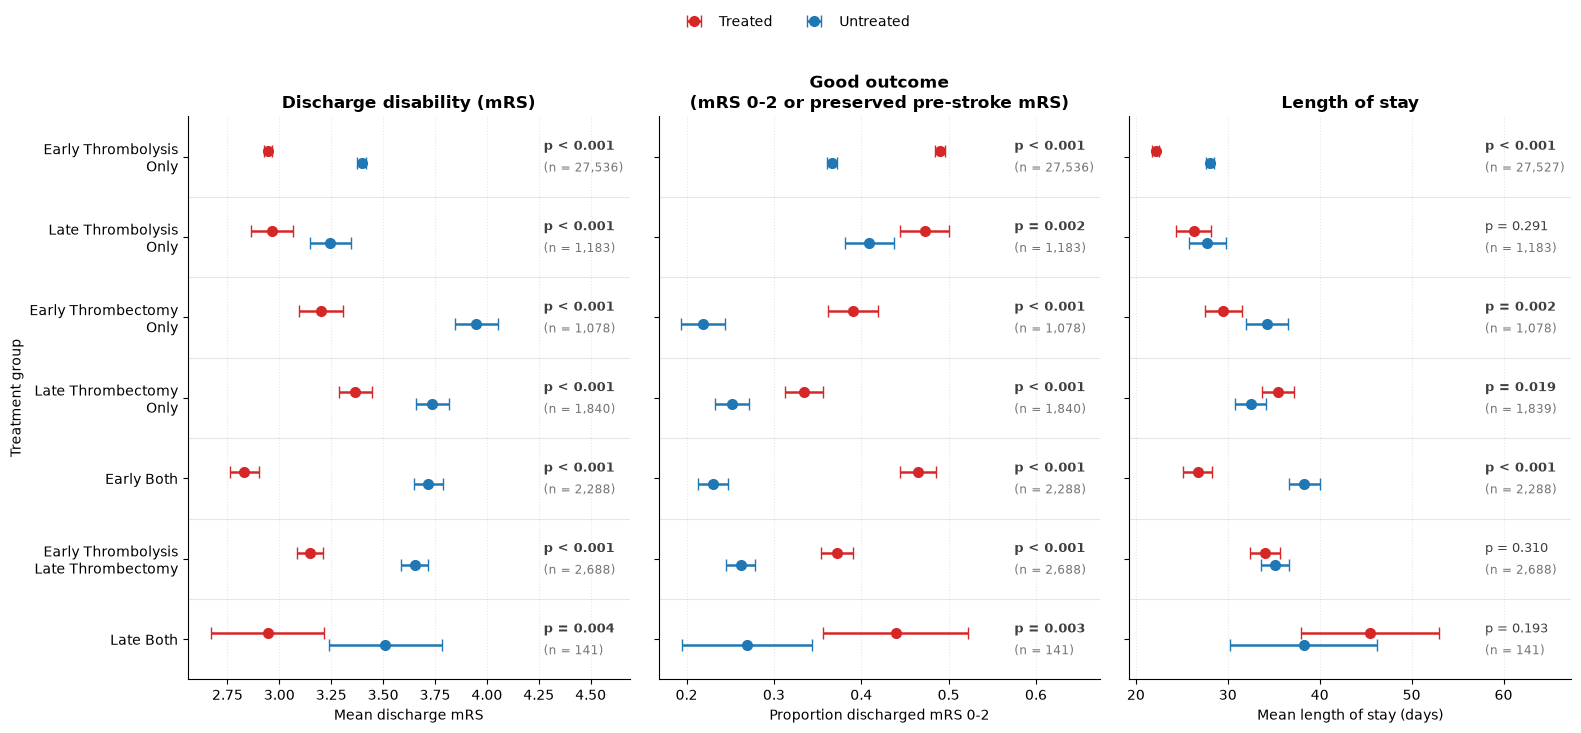

In [13]:
panels = [
    (summary_df, "Discharge disability (mRS)", "Mean discharge mRS"),
    (summary_df_target, "Good outcome\n(mRS 0-2 or preserved pre-stroke mRS)",
     f"Proportion discharged mRS 0-{MRS_TARGET}"),
    (length_of_stay_df, "Length of stay", "Mean length of stay (days)"),
]

C_T, C_U = "#d62728", "#1f77b4"   # treated, untreated
OFF = 0.18                        # vertical offset between treated and untreated points
SPACING = 2.4                     # vertical spacing between strategies

fig, axes = plt.subplots(1, 3, figsize=(16, 8), sharey=True)

for ax, (df, title, xlabel) in zip(axes, panels):
    # First strategy at the top
    df = df.set_index("treatment_group").reindex(GROUP_ORDER[::-1]).dropna(how="all").reset_index()
    y = np.arange(len(df), dtype=float) * SPACING

    for suffix, offset, colour, label in [("treated", OFF, C_T, "Treated"),
                                          ("untreated", -OFF, C_U, "Untreated")]:
        mean = df[f"{suffix}_mean"].to_numpy(dtype=float)
        lower = df[f"{suffix}_ci_lower"].to_numpy(dtype=float)
        upper = df[f"{suffix}_ci_upper"].to_numpy(dtype=float)
        ax.errorbar(mean, y + offset, xerr=[mean - lower, upper - mean], fmt="o",
                    color=colour, ecolor=colour, markersize=7, capsize=4,
                    elinewidth=1.8, label=label, zorder=3)

    # p-values and n to the right of the points
    xmax = max(df["treated_ci_upper"].max(), df["untreated_ci_upper"].max())
    xmin = min(df["treated_ci_lower"].min(), df["untreated_ci_lower"].min())
    span = max(xmax - xmin, 1e-9)
    xtext = xmax + 0.16 * span
    for yi, p_value, n in zip(y, df["p_value"], df["matched_n"]):
        p_text = "p < 0.001" if p_value < 0.001 else f"p = {p_value:.3f}"
        ax.text(xtext, yi + 0.30, p_text, va="center", ha="left", fontsize=9,
                fontweight="bold" if p_value < 0.05 else "normal", color="0.25")
        ax.text(xtext, yi - 0.34, f"(n = {int(n):,})", va="center", ha="left",
                fontsize=8.5, color="0.45")
    ax.set_xlim(xmin - 0.08 * span, xtext + 0.30 * span)

    for yi in y[:-1]:
        ax.axhline(yi + SPACING / 2, color="0.9", lw=0.8, zorder=0)
    ax.set_ylim(y[0] - SPACING / 2, y[-1] + SPACING / 2)
    ax.set_yticks(y)
    ax.set_yticklabels([GROUP_LABELS[g] for g in df["treatment_group"]])
    ax.set_xlabel(xlabel)
    ax.set_title(title, fontweight="bold")
    ax.grid(axis="x", alpha=0.3, linestyle=":")
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)

axes[0].set_ylabel("Treatment group")
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="lower center", ncol=2, frameon=False,
           bbox_to_anchor=(0.5, 0.92))
fig.tight_layout(rect=(0, 0.05, 1, 0.90))
fig.savefig(f"{OUTPUT_DIR}/{prefix}.png", dpi=300)
plt.show()

**What this shows:** in all three panels, treated patients (red) do better than their matched controls (blue) for the early strategies. The good-outcome panel also shows how much the control groups differ between strategies. Controls for thrombectomy groups have much lower good-outcome rates than controls for thrombolysis-only groups, because they are matched to more severe strokes.

## Sensitivity analyses

These analyses test whether the main result (the difference in the proportion with a good outcome) depends on choices made in the analysis. Each one changes **one** choice and keeps everything else as in the primary analysis.

| Category | Analysis | Why |
|---|---|---|
| Inference | Cluster-robust confidence interval | The primary CI treats treated and control groups as independent. Here, standard errors are clustered on the control patient, so pairs that share a control are not treated as independent. |
| Matching | Control used once only / up to 5 times / unlimited | Tests the choice of `MAX_CONTROL_REUSE` (k = 3). |
| Matching | Match on exact NIHSS instead of 5-point band | Tests residual confounding by stroke severity within bands. |
| Matching | Also match on congestive heart failure, hypertension, diabetes | Tests confounding by comorbidities that are described but not matched. |
| Matching | Also match on large vessel occlusion | Patients having thrombectomy nearly all have an LVO; untreated controls may not. |
| Treatment timing | Early/late cut-off of 240 or 300 minutes | Tests the choice of `CUTOFF` = 270 minutes. |
| Cohort | All teams / teams with at least 20 thrombectomies | Tests the team thrombectomy-volume restriction (at least 10). |
| Cohort | Include patients who had perfusion imaging | Tests the exclusion of perfusion imaging. |
| Outcome | mRS 0–2 only; mRS 0–1 or no worse than before stroke; mRS 0–3 or no worse than before stroke | Tests the good-outcome definition. |
| Matching | 20 different random seeds | The control is picked at random from the matching stratum, so the estimate varies with the seed. |
| Unmeasured confounding | E-values | How strong an unmeasured confounder would have to be to explain away the result. |

In [14]:
def summarise_effects(matched, analysis, category, outcome_fn=good_outcome, clustered=False):
    # Difference in proportion with a good outcome (treated - control), with 95% CI.
    # clustered=False: pooled two-sample t interval, as in the primary analysis.
    # clustered=True: linear probability model, SEs clustered on the control patient,
    #                 so pairs sharing a control are not treated as independent.
    rows = []
    for strategy, s in matched.items():
        y_t = outcome_fn(s["treated"]).to_numpy(dtype=float)
        y_c = outcome_fn(s["untreated"]).to_numpy(dtype=float)
        if clustered:
            y = np.concatenate([y_t, y_c])
            X = sm.add_constant(np.concatenate([np.ones(len(y_t)), np.zeros(len(y_c))]))
            control_id = s["untreated"]["patient_id"].to_numpy()
            fit = sm.OLS(y, X).fit(cov_type="cluster",
                                   cov_kwds={"groups": np.concatenate([control_id, control_id])})
            diff, (lower, upper), p_value = fit.params[1], fit.conf_int()[1], fit.pvalues[1]
        else:
            compare = sm.stats.CompareMeans(sm.stats.DescrStatsW(y_t), sm.stats.DescrStatsW(y_c))
            diff = y_t.mean() - y_c.mean()
            lower, upper = compare.tconfint_diff(alpha=0.05, usevar="pooled")
            p_value = compare.ttest_ind(usevar="pooled")[1]
        rows.append({
            "category": category,
            "analysis": analysis,
            "treatment_group": strategy,
            "matched_n": len(y_t),
            "percent_matched": s["percent_matched"],
            "treated_proportion": y_t.mean(),
            "control_proportion": y_c.mean(),
            "difference": diff,
            "ci_lower": lower,
            "ci_upper": upper,
            "p_value": p_value,
        })
    return pd.DataFrame(rows)


_cohorts = {}

def get_cohort(**cohort_kwargs):
    # Build (and cache) a cohort with non-default eligibility or cut-off settings
    key = tuple(sorted(cohort_kwargs.items()))
    if key not in _cohorts:
        _cohorts[key] = build_cohort(raw_data, **cohort_kwargs)
    return _cohorts[key]

In [15]:
severity_exact = [f if f != "stroke_severity_band" else "stroke_severity" for f in MATCHING_FEATURES]
with_comorbidities = MATCHING_FEATURES + ["congestive_heart_failure", "hypertension", "diabetes"]
with_lvo = MATCHING_FEATURES + ["lvo"]

# (category, label, cohort settings, matching settings)
SCENARIOS = [
    ("Matching", "Controls used once only (k = 1)", {}, {"max_control_reuse": 1}),
    ("Matching", "Controls used up to 5 times (k = 5)", {}, {"max_control_reuse": 5}),
    ("Matching", "Unlimited control reuse", {}, {"max_control_reuse": None}),
    ("Matching", "Match on exact NIHSS (not band)", {}, {"matching_features": severity_exact}),
    ("Matching", "Also match on CHF, hypertension, diabetes", {}, {"matching_features": with_comorbidities}),
    ("Matching", "Also match on LVO", {}, {"matching_features": with_lvo}),
    ("Treatment timing", "Early/late cut-off 240 min", {"cutoff": 240}, {}),
    ("Treatment timing", "Early/late cut-off 300 min", {"cutoff": 300}, {}),
    ("Cohort", "All teams (no thrombectomy-volume limit)", {"min_team_thrombectomies": 0}, {}),
    ("Cohort", "Teams with at least 20 thrombectomies", {"min_team_thrombectomies": 20}, {}),
    ("Cohort", "Include perfusion imaging patients", {"exclude_perfusion_imaging": False}, {}),
]

# Alternative good-outcome definitions, applied to the primary matched samples
OUTCOME_SCENARIOS = [
    ("mRS 0-2 only", lambda d: good_outcome(d, 2, allow_no_worse_than_prior=False)),
    ("mRS 0-1 or no worse than pre-stroke", lambda d: good_outcome(d, 1)),
    ("mRS 0-3 or no worse than pre-stroke", lambda d: good_outcome(d, 3)),
]

results = [
    summarise_effects(matched_samples, "Primary", "Primary"),
    summarise_effects(matched_samples, "Cluster-robust CI (clustered on control)", "Inference", clustered=True),
]
for category, label, cohort_kwargs, match_kwargs in SCENARIOS:
    print(f"Running: {label}")
    cohort = get_cohort(**cohort_kwargs) if cohort_kwargs else data
    results.append(summarise_effects(match_groups(cohort, **match_kwargs), label, category))
for label, outcome_fn in OUTCOME_SCENARIOS:
    results.append(summarise_effects(matched_samples, f"Outcome: {label}", "Outcome definition",
                                     outcome_fn=outcome_fn))

sensitivity_df = pd.concat(results, ignore_index=True)
sensitivity_df["difference_publish_pp"] = sensitivity_df.apply(
    lambda r: f"{100 * r['difference']:.1f} ({100 * r['ci_lower']:.1f}, {100 * r['ci_upper']:.1f})", axis=1)
sensitivity_df.to_csv(f"{OUTPUT_DIR}/{prefix}_sensitivity.csv", index=False)
analysis_order = list(dict.fromkeys(sensitivity_df["analysis"]))


def sensitivity_pivot(values):
    # Rows = analysis, columns = treatment strategy
    table = (sensitivity_df.pivot(index="analysis", columns="treatment_group", values=values)
             .reindex(index=analysis_order, columns=[g for g in GROUP_ORDER if g in set(sensitivity_df["treatment_group"])]))
    table.columns = [c.replace("_", " ") for c in table.columns]
    return table


# Difference in good outcome, percentage points (95% CI)
sensitivity_table = sensitivity_pivot("difference_publish_pp")
sensitivity_table.to_csv(f"{OUTPUT_DIR}/{prefix}_sensitivity_table.csv")
sensitivity_table

Running: Controls used once only (k = 1)
Running: Controls used up to 5 times (k = 5)
Running: Unlimited control reuse
Running: Match on exact NIHSS (not band)
Running: Also match on CHF, hypertension, diabetes
Running: Also match on LVO
Running: Early/late cut-off 240 min
Running: Early/late cut-off 300 min
Running: All teams (no thrombectomy-volume limit)
Running: Teams with at least 20 thrombectomies
Running: Include perfusion imaging patients


,early thrombolysis only,late thrombolysis only,early thrombectomy only,late thrombectomy only,early both,early thrombolysis late thrombectomy,late both
analysis,,,,,,,
Primary,"12.4 (11.6, 13.2)","6.3 (2.3, 10.3)","17.2 (13.3, 21.0)","8.3 (5.3, 11.2)","23.5 (20.8, 26.2)","11.0 (8.5, 13.4)","17.0 (5.9, 28.1)"
Cluster-robust CI (clustered on control),"12.4 (11.5, 13.3)","6.3 (2.6, 10.0)","17.2 (13.5, 20.8)","8.3 (5.5, 11.1)","23.5 (20.9, 26.1)","11.0 (8.5, 13.5)","17.0 (6.6, 27.4)"
Controls used once only (k = 1),"11.6 (10.6, 12.5)","6.9 (2.9, 10.9)","16.7 (12.9, 20.6)","7.2 (4.2, 10.1)","22.8 (20.1, 25.5)","9.7 (7.2, 12.2)","17.0 (5.9, 28.1)"
Controls used up to 5 times (k = 5),"12.5 (11.7, 13.3)","6.3 (2.3, 10.3)","17.2 (13.3, 21.0)","8.2 (5.3, 11.1)","23.1 (20.4, 25.7)","10.5 (8.1, 13.0)","17.0 (5.9, 28.1)"
Unlimited control reuse,"12.7 (11.9, 13.5)","6.3 (2.3, 10.3)","17.2 (13.3, 21.0)","8.2 (5.3, 11.1)","23.0 (20.3, 25.7)","10.5 (8.1, 13.0)","17.0 (5.9, 28.1)"
Match on exact NIHSS (not band),"12.6 (11.7, 13.4)","8.7 (4.7, 12.7)","18.8 (14.9, 22.7)","7.2 (4.2, 10.2)","24.4 (21.6, 27.1)","11.3 (8.8, 13.8)","16.8 (5.5, 28.0)"
"Also match on CHF, hypertension, diabetes","12.3 (11.4, 13.1)","9.1 (5.0, 13.1)","12.6 (8.5, 16.7)","4.5 (1.4, 7.6)","23.5 (20.7, 26.2)","8.3 (5.8, 10.9)","18.2 (7.0, 29.5)"
Also match on LVO,"13.2 (11.3, 15.1)","9.3 (1.9, 16.7)","20.5 (12.8, 28.2)","17.0 (11.3, 22.8)","30.9 (25.5, 36.3)","21.1 (16.1, 26.2)","27.3 (9.8, 44.8)"
Early/late cut-off 240 min,"13.1 (12.3, 14.0)","8.9 (6.6, 11.2)","16.9 (12.3, 21.4)","6.2 (3.5, 9.0)","23.6 (20.4, 26.8)","13.0 (10.7, 15.3)","11.4 (4.8, 17.9)"


In [16]:
# Percentage of treated patients matched in each analysis.
# Low values mean the matched patients may not represent all treated patients.
sensitivity_pivot("percent_matched").round(1)

,early thrombolysis only,late thrombolysis only,early thrombectomy only,late thrombectomy only,early both,early thrombolysis late thrombectomy,late both
analysis,,,,,,,
Primary,99.4,99.5,97.4,98.1,99.1,99.0,100.0
Cluster-robust CI (clustered on control),99.4,99.5,97.4,98.1,99.1,99.0,100.0
Controls used once only (k = 1),74.6,99.5,96.7,97.4,97.9,98.7,100.0
Controls used up to 5 times (k = 5),99.6,99.5,97.4,98.1,99.2,99.0,100.0
Unlimited control reuse,99.7,99.5,97.4,98.1,99.2,99.0,100.0
Match on exact NIHSS (not band),96.7,97.9,90.2,91.8,95.3,95.8,97.2
"Also match on CHF, hypertension, diabetes",96.2,96.6,89.0,91.4,94.9,95.3,97.2
Also match on LVO,19.1,29.0,22.5,25.4,22.4,22.7,39.0
Early/late cut-off 240 min,99.5,99.6,97.4,98.0,98.9,99.1,99.7


**What this shows:**

* **Confidence intervals that allow for matching** are almost identical to the primary ones. Ignoring the pairing and the reuse of controls makes little practical difference.
* **Control reuse (k)** changes the estimates by about 1 point or less. With each control used only once, only 75% of early thrombolysis patients can be matched, because there are not enough controls. That row therefore covers a different set of patients.
* **Matching on exact NIHSS** changes the estimates by up to 2.4 points, with no consistent direction.
* **Also matching on comorbidities** gives the largest falls, all in thrombectomy-based strategies:
  * early thrombectomy only: 17.2 → 12.6 points
  * late thrombectomy only: 8.3 → 4.5 points
  * early thrombolysis, late thrombectomy: 11.0 → 8.3 points

  Thrombolysis-only strategies and early both hardly change. This matches the diabetes imbalance seen above. All CIs still exclude zero.
* **Also matching on LVO** is possible for only 19–39% of treated patients, because few untreated patients have a matching LVO record. Among those who can be matched, the thrombectomy-based strategies show much larger effects:
  * late thrombectomy only: 17.0 points
  * early thrombolysis, late thrombectomy: 21.1 points
  * early both: 30.9 points

  This fits the expectation that untreated patients with an LVO do badly, so the primary analysis may *underestimate* the benefit of thrombectomy. The matched patients are a small, selected subset, though, so this result should be read with caution.
* **The early/late cut-off (240 or 300 min)** changes the size of the effects but not their direction. Moving the cut-off also changes which patients count as early or late.
* **Cohort restrictions** (team thrombectomy volume, including perfusion imaging) move the estimates by a few points. With teams giving at least 20 thrombectomies, the late-both CI nearly reaches zero (0.1).
* **Outcome definition:**
  * Dropping "no worse than pre-stroke" makes little difference.
  * The stricter mRS 0–1 outcome roughly halves the differences for the thrombectomy-based strategies, because fewer patients reach it. For late both, the CI then includes zero (−2.5 to 15.3).
  * The looser mRS 0–3 outcome slightly increases most differences.

### Forest plot

Each panel is one treatment strategy. Points are the difference in the proportion with a good outcome (treated minus matched controls, percentage points) with 95% CI. The dashed line is the primary estimate; the grey line is no difference.

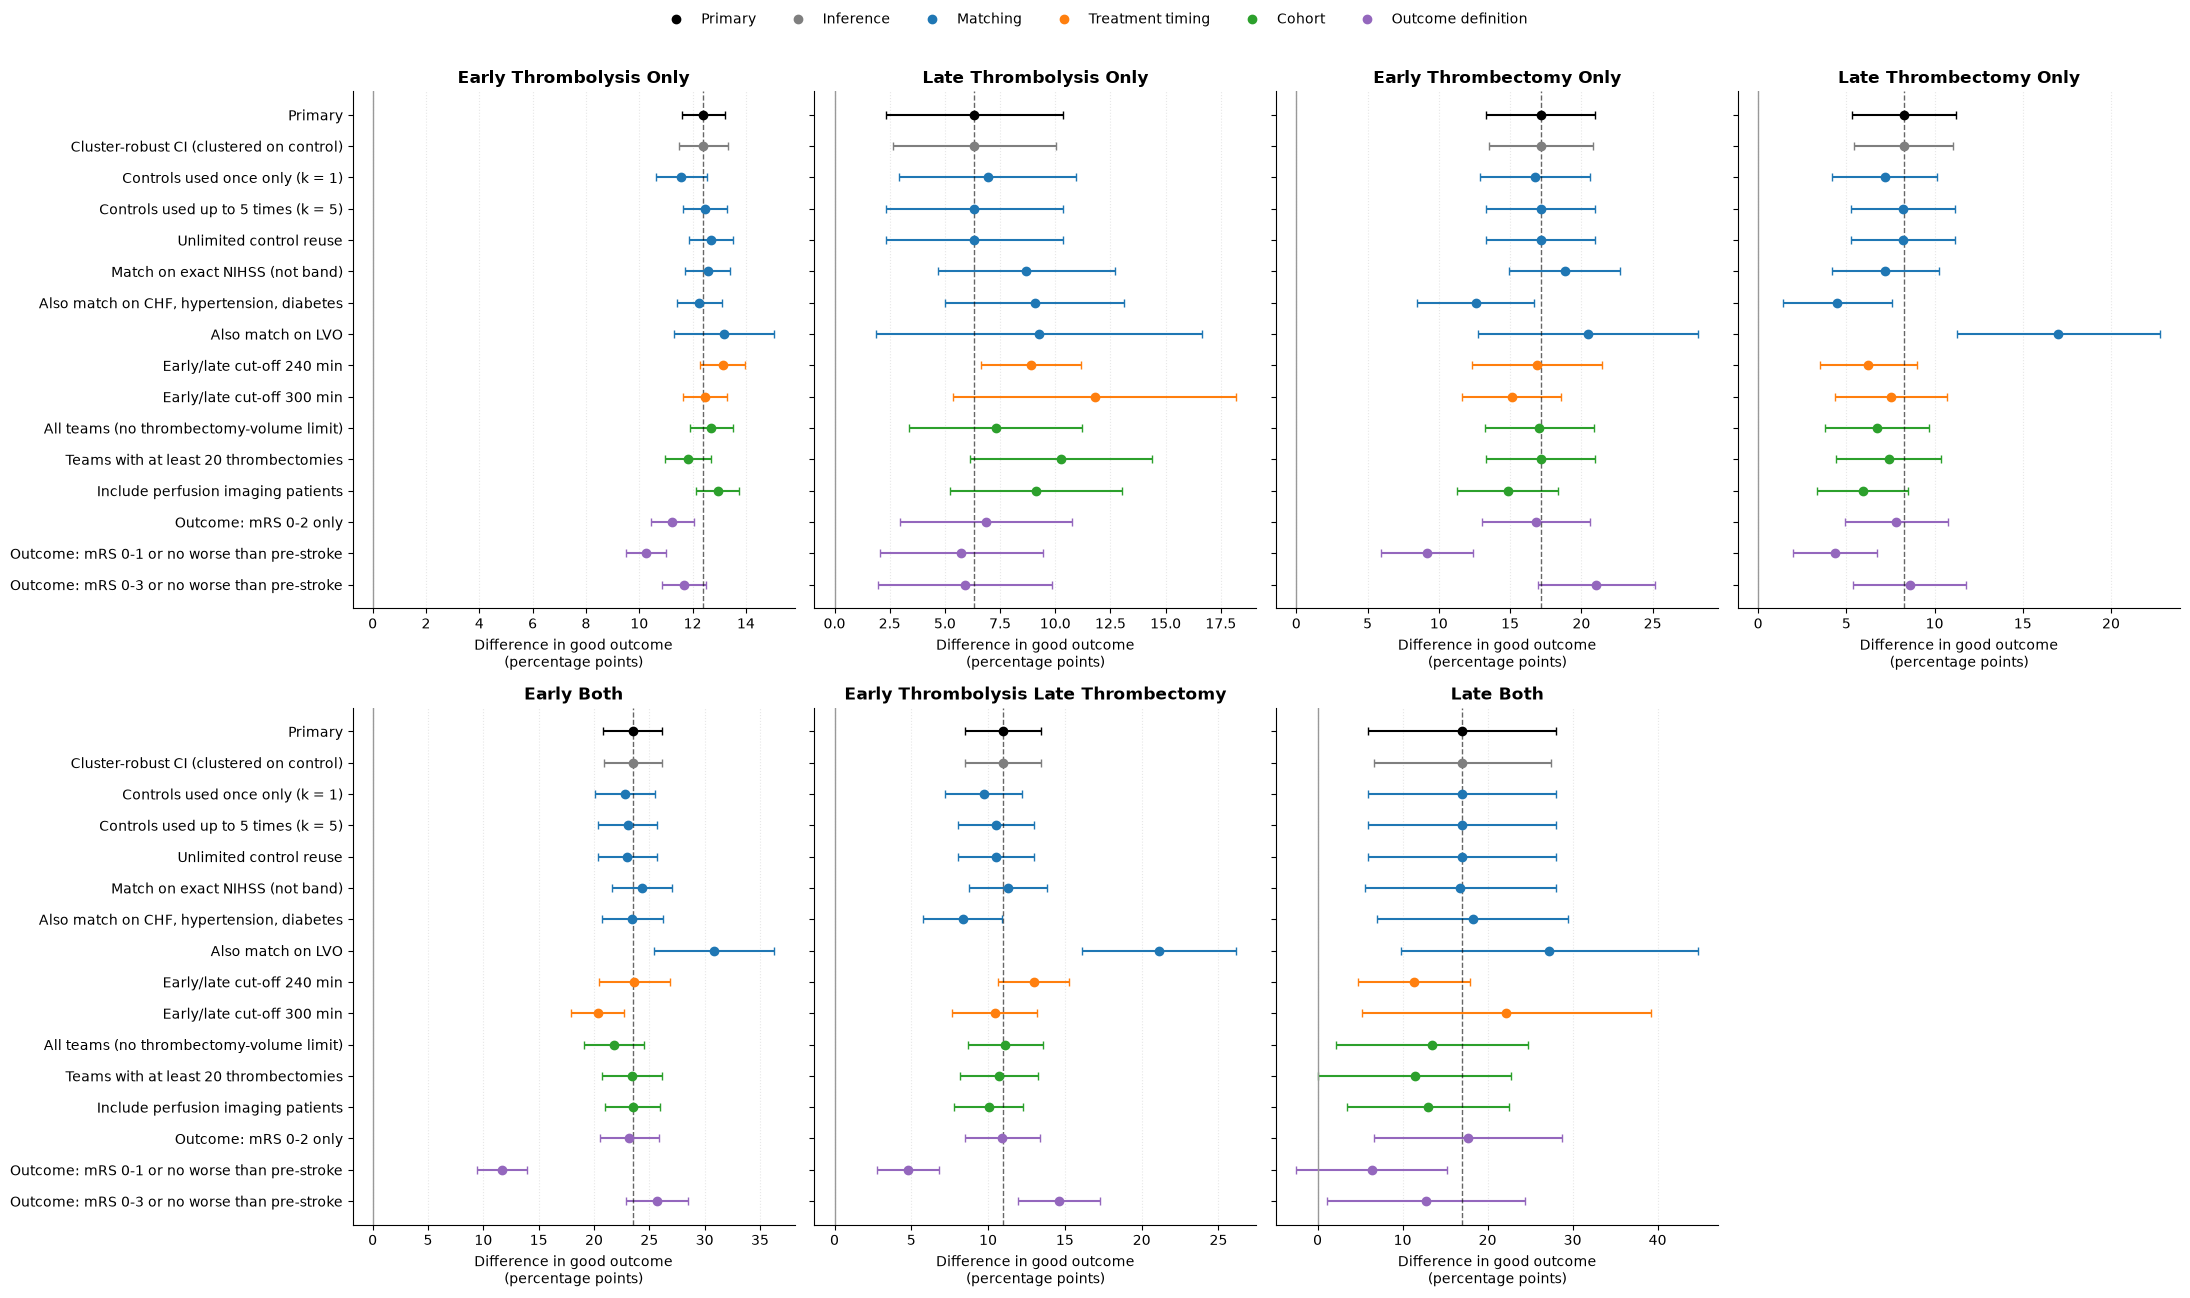

In [17]:
category_colours = {
    "Primary": "black",
    "Inference": "#7f7f7f",
    "Matching": "#1f77b4",
    "Treatment timing": "#ff7f0e",
    "Cohort": "#2ca02c",
    "Outcome definition": "#9467bd",
}
strategies = [g for g in GROUP_ORDER if g in set(sensitivity_df["treatment_group"])]
n_cols = 4
n_rows = int(np.ceil(len(strategies) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(22, 6.5 * n_rows), sharey=True)
axes = np.atleast_1d(axes).ravel()
y_pos = {a: i for i, a in enumerate(analysis_order[::-1])}  # primary at the top

for ax, strategy in zip(axes, strategies):
    df = sensitivity_df[sensitivity_df["treatment_group"] == strategy]
    for _, r in df.iterrows():
        colour = category_colours[r["category"]]
        ax.errorbar(100 * r["difference"], y_pos[r["analysis"]],
                    xerr=[[100 * (r["difference"] - r["ci_lower"])], [100 * (r["ci_upper"] - r["difference"])]],
                    fmt="o", color=colour, ecolor=colour, capsize=3, markersize=6)
    primary = df.loc[df["analysis"] == "Primary", "difference"]
    ax.axvline(100 * primary.iloc[0], color="black", linestyle="--", lw=1, alpha=0.6)
    ax.axvline(0, color="0.6", lw=1)
    ax.set_title(GROUP_LABELS[strategy].replace("\n", " "), fontweight="bold")
    ax.set_xlabel("Difference in good outcome\n(percentage points)")
    ax.grid(axis="x", alpha=0.3, linestyle=":")
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)

for ax in axes[len(strategies):]:
    ax.axis("off")

axes[0].set_yticks(list(y_pos.values()))
axes[0].set_yticklabels(list(y_pos.keys()))
for i in range(0, len(axes), n_cols):
    axes[i].tick_params(labelleft=True)

handles = [plt.Line2D([], [], marker="o", color=c, linestyle="", label=k) for k, c in category_colours.items()]
fig.legend(handles=handles, loc="upper center", ncol=len(handles), frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(f"{OUTPUT_DIR}/{prefix}_sensitivity.png", dpi=300)
plt.show()

### Variation from the random choice of control

When several untreated patients match a treated patient, one is picked at random. Repeating the matching with 20 different random seeds shows how much the estimate moves because of that choice alone. Seeds are spaced widely apart so that runs do not share random draws.

In [18]:
N_SEEDS = 20
seed_df = pd.concat(
    [summarise_effects(match_groups(data, base_seed=1_000_003 * i), f"Seed {i}", "Seed")
     for i in range(1, N_SEEDS + 1)],
    ignore_index=True)
seed_df.to_csv(f"{OUTPUT_DIR}/{prefix}_sensitivity_seeds.csv", index=False)

# Differences in percentage points
primary_effects = sensitivity_df[sensitivity_df["analysis"] == "Primary"].set_index("treatment_group")
seed_summary = (
    seed_df.groupby("treatment_group")["difference"]
    .agg(median="median", minimum="min", maximum="max")
    .mul(100)
    .reindex(strategies)
    .round(1)
)
seed_summary["primary"] = primary_effects["difference"].mul(100).round(1)
seed_summary["n_seeds_ci_excluding_zero"] = (
    seed_df.assign(excludes_zero=(seed_df["ci_lower"] > 0) | (seed_df["ci_upper"] < 0))
    .groupby("treatment_group")["excludes_zero"].sum()
)
seed_summary

,median,minimum,maximum,primary,n_seeds_ci_excluding_zero
treatment_group,,,,,
early_thrombolysis_only,12.6,12.1,13.0,12.4,20
late_thrombolysis_only,8.4,5.9,10.7,6.3,20
early_thrombectomy_only,15.7,12.8,18.5,17.2,20
late_thrombectomy_only,6.1,4.6,8.6,8.3,20
early_both,22.2,21.0,23.5,23.5,20
early_thrombolysis_late_thrombectomy,9.9,8.3,12.1,11.0,20
late_both,15.2,5.7,19.1,17.0,18


**What this shows:**

* For **early thrombolysis only** (the largest group), the estimate hardly moves: 12.1 to 13.0 points across 20 seeds.
* For the **smaller groups** the choice of control matters more:
  * early thrombectomy only: 12.8 to 18.5 points (median 15.7; primary seed 17.2)
  * late thrombolysis only: 5.9 to 10.7 (median 8.4; primary 6.3)
  * late both: 5.7 to 19.1 (median 15.2; primary 17.0)
* The primary seed is not unusual, but it is not the median either. Reporting the median across seeds, or averaging over several matchings, would reduce this source of variation.
* The 95% CI excludes zero for every seed in every strategy, except late both, where it does so for 18 of 20 seeds.

### E-values for unmeasured confounding

The E-value is the minimum strength of association, on the risk-ratio scale, that an unmeasured confounder would need to have with **both** the treatment and the outcome (beyond the matched variables) to fully explain away the observed effect. The E-value for the CI is the same quantity for the confidence limit closest to no effect; a value of 1 means the CI already includes no effect.

VanderWeele TJ, Ding P. Sensitivity analysis in observational research: introducing the E-value. *Ann Intern Med* 2017;167:268–274.

Risk ratios are treated proportion / control proportion with a log-scale 95% CI, ignoring the matching (as for the primary CI).

In [19]:
def e_value(rr):
    rr = np.asarray(rr, dtype=float)
    rr = np.where(rr < 1, 1 / rr, rr)
    return rr + np.sqrt(rr * (rr - 1))

ev = primary_effects.reindex(strategies).reset_index()
p_t, p_c, n = ev["treated_proportion"], ev["control_proportion"], ev["matched_n"]
ev["risk_ratio"] = p_t / p_c
se_log_rr = np.sqrt((1 - p_t) / (n * p_t) + (1 - p_c) / (n * p_c))
ev["rr_ci_lower"] = np.exp(np.log(ev["risk_ratio"]) - 1.96 * se_log_rr)
ev["rr_ci_upper"] = np.exp(np.log(ev["risk_ratio"]) + 1.96 * se_log_rr)
ev["e_value"] = e_value(ev["risk_ratio"])

# E-value for the CI limit closest to no effect (1 if the CI includes no effect)
closest_limit = np.where(ev["risk_ratio"] >= 1, ev["rr_ci_lower"], ev["rr_ci_upper"])
crosses_null = (ev["rr_ci_lower"] <= 1) & (ev["rr_ci_upper"] >= 1)
ev["e_value_ci"] = np.where(crosses_null, 1.0, e_value(closest_limit))

ev_out = ev[["treatment_group", "matched_n", "risk_ratio", "rr_ci_lower", "rr_ci_upper", "e_value", "e_value_ci"]]
ev_out.to_csv(f"{OUTPUT_DIR}/{prefix}_e_values.csv", index=False)
ev_out.round(2)

,treatment_group,matched_n,risk_ratio,rr_ci_lower,rr_ci_upper,e_value,e_value_ci
0,early_thrombolysis_only,27536,1.34,1.31,1.37,2.01,1.95
1,late_thrombolysis_only,1183,1.15,1.05,1.27,1.58,1.29
2,early_thrombectomy_only,1078,1.78,1.56,2.04,2.97,2.49
3,late_thrombectomy_only,1840,1.33,1.20,1.47,1.99,1.69
4,early_both,2288,2.02,1.85,2.21,3.46,3.11
5,early_thrombolysis_late_thrombectomy,2688,1.42,1.31,1.54,2.19,1.95
6,late_both,141,1.63,1.17,2.27,2.65,1.62


**What this shows:**

* **Point-estimate E-values** range from 1.58 (late thrombolysis only) to 3.46 (early thrombolysis plus early thrombectomy).
* **Strongest:** for early thrombolysis plus early thrombectomy, an unmeasured confounder would need a risk ratio of at least 3.1 with both treatment and good outcome to move the CI to include no effect. That is a strong confounder, given that the main prognostic factors (age, severity, pre-stroke disability) are already matched.
* **Weakest:** for late thrombolysis only, the CI E-value is 1.29, so quite modest unmeasured confounding could explain the result.

## Conclusions and limitations

### Conclusions

* In early-arriving patients with non-mild stroke, every thrombolysis and thrombectomy strategy is associated with more good outcomes at discharge than in similar untreated patients.
* The association is larger when treatment is given earlier, and largest when early thrombolysis is followed by early thrombectomy.
* The findings hold across most of the sensitivity analyses, for these reasons:
  * the confidence interval method makes almost no difference
  * the early/late cut-off, cohort restrictions, control reuse and outcome definition change the size of the effects but not their direction
  * except in the small late-both group, CIs exclude zero in every analysis

### Limitations

* **Unmeasured confounding.** Treatment was not randomised. Reasons for not treating (for example contraindications, rapidly improving symptoms, frailty, or imaging findings) are not fully captured by the matching features and could bias the results in either direction. The E-values show how strong such confounding would need to be.
* **Sensitivity to added matching features.** Adding comorbidities to the matching reduces the estimated benefit of thrombectomy-based strategies, in line with the remaining imbalance in diabetes. This suggests some residual confounding by health status in the primary analysis.
* **LVO not matched.** Nearly all thrombectomy patients have an LVO, but the primary matching does not use LVO status because few untreated patients have it recorded. Matching on LVO where possible gives larger thrombectomy effects. The primary analysis may therefore be conservative for thrombectomy, but that subset is small and selected.
* **Timing of treatment and time zero.** Strategies are defined by when treatment was actually given. A patient who died or deteriorated before they could be treated late is counted as untreated. This can favour the late-treatment strategies.
* **Each strategy has its own controls.** Differences between strategies are not head-to-head comparisons in the same patients.
* **Outcome at discharge.** mRS at discharge is not the 90-day mRS used in most trials, and depends on length of stay and discharge arrangements.
* **Small late-treatment groups**, especially late thrombolysis plus late thrombectomy (141 patients), give imprecise estimates that vary with the random choice of control.